# Apresentação do Sistema

Este notebook apresenta o modelo utilizado no trabalho.

O modelo é baseado em Pourkargar, Almansoori e Daoutidis (2017), com uma diferença: **aqui os volumes das três unidades são considerados constantes**. No artigo, cada volume $V_i$ é um estado com seu próprio balanço de volume, mas esse balanço tem comportamento integrador. Com $V_i$ constante, os volumes passam a ser parâmetros e as vazões internas deixam de ser variáveis dinâmicas, tornando-se relações algébricas das entradas.

O resultado é um sistema com 3 entradas e 9 estados:

$$\mathbf{u} = \begin{bmatrix} F_{f1} & F_{f2} & F_R \end{bmatrix}^\top, \qquad \mathbf{x} = \begin{bmatrix} T_1 & T_2 & T_3 & x_{A1} & x_{B1} & x_{A2} & x_{B2} & x_{A3} & x_{B3} \end{bmatrix}^\top$$

## Modelo

### 🌡️ Temperaturas

$$\frac{dT_1}{dt} = \frac{F_{f1}}{V_1}(T_0 - T_1) + \frac{F_R}{V_1}(T_3 - T_1) + \frac{Q_1}{\rho C_p V_1} - \frac{m}{C_p}\left(k_{11} x_{A1} \Delta H_{r1} + k_{21} x_{B1} \Delta H_{r2}\right)$$

$$\frac{dT_2}{dt} = \frac{F_{f2}}{V_2}(T_0 - T_2) + \frac{F_1}{V_2}(T_1 - T_2) + \frac{Q_2}{\rho C_p V_2} - \frac{m}{C_p}\left(k_{12} x_{A2} \Delta H_{r1} + k_{22} x_{B2} \Delta H_{r2}\right)$$

$$\frac{dT_3}{dt} = \frac{F_2}{V_3}(T_2 - T_3) + \frac{Q_3}{\rho C_p V_3}$$

### 🧪 Frações molares

$$\frac{dx_{A1}}{dt} = \frac{F_{f1}}{V_1}(x_{A0} - x_{A1}) + \frac{F_R}{V_1}(x_{AR} - x_{A1}) - k_{11} x_{A1}$$

$$\frac{dx_{B1}}{dt} = \frac{F_R}{V_1}(x_{BR} - x_{B1}) - \frac{F_{f1}}{V_1} x_{B1} + k_{11} x_{A1} - k_{21} x_{B1}$$

$$\frac{dx_{A2}}{dt} = \frac{F_{f2}}{V_2}(x_{A0} - x_{A2}) + \frac{F_1}{V_2}(x_{A1} - x_{A2}) - k_{12} x_{A2}$$

$$\frac{dx_{B2}}{dt} = \frac{F_1}{V_2}(x_{B1} - x_{B2}) - \frac{F_{f2}}{V_2} x_{B2} + k_{12} x_{A2} - k_{22} x_{B2}$$

$$\frac{dx_{A3}}{dt} = \frac{F_2}{V_3}(x_{A2} - x_{A3}) - \frac{F_P + F_R}{V_3}(x_{AR} - x_{A3})$$

$$\frac{dx_{B3}}{dt} = \frac{F_2}{V_3}(x_{B2} - x_{B3}) - \frac{F_P + F_R}{V_3}(x_{BR} - x_{B3})$$

Onde:

- $V_i$: volume da unidade $i$ [m³], constante
- $T_i$: temperatura da unidade $i$ [K]
- $x_{Ai}$, $x_{Bi}$: frações molares dos componentes A e B na unidade $i$ [-]
- $F_{f1}$, $F_{f2}$: vazões de alimentação dos reatores 1 e 2 [m³/h]
- $F_1$, $F_2$: vazões de saída dos reatores 1 e 2 [m³/h]
- $F_3$: vazão de produto retirada do separador [m³/h]
- $F_R$: vazão de reciclo [m³/h]
- $F_P$: vazão de purga [m³/h]
- $Q_1$, $Q_2$, $Q_3$: taxas de calor fornecidas aos reatores 1 e 2 e ao separador [kJ/h]
- $T_0$: temperatura de alimentação [K]
- $x_{A0}$: fração molar de A na alimentação [-]
- $\rho$: massa específica do fluido [kg/m³]
- $C_p$: calor específico do fluido [kJ/(kg·K)]
- $m$: molalidade [kmol/kg]
- $\Delta H_{rj}$: entalpia da reação $j$ [kJ/kmol]
- $x_{AR}$, $x_{BR}$: frações molares de A e B na corrente de reciclo [-]

### 💧 Vazões internas

Com volumes constantes, as vazões internas ficam determinadas pelas entradas:

$$F_1 = F_{f1} + F_R$$

$$F_2 = F_{f2} + F_1$$

$$F_3 = F_2 - F_P - F_R$$

$$F_P = \varepsilon \, F_R$$

em que $\varepsilon$ é a razão de purga [-].

### ⚗️ Cinética das reações

Os coeficientes de velocidade das reações seguem a lei de Arrhenius:

$$k_{ri} = k_r^0 \exp\!\left(-\frac{E_r}{R\,T_i}\right), \qquad r = 1, 2, \quad i = 1, 2$$

Onde:

- $k_r^0$: fator pré-exponencial da reação $r$ [1/s]
- $E_r$: energia de ativação da reação $r$ [kJ/kmol]
- $R$: constante universal dos gases [kJ/(kmol·K)]
- $T_i$: temperatura do reator $i$ [K]

### 🔁 Composição da corrente de reciclo

As frações molares da corrente de reciclo são calculadas supondo equilíbrio líquido-vapor no separador:

$$x_{SR} = \frac{\alpha_S \, x_{S3}}{\displaystyle\sum_{S \in \{A,B,C\}} \alpha_S \, x_{S3}}, \qquad S = A, B, C$$

Onde:

- $\alpha_S$: volatilidade relativa do componente $S$ [-]
- $x_{S3}$: fração molar do componente $S$ no separador [-], com $x_{C3} = 1 - x_{A3} - x_{B3}$

## Simulação

O código a seguir carrega o modelo não linear e o integra com `solve_ivp`, partindo do ponto de operação em regime estacionário (`y0`). A simulação é repetida para cada entrada e em cada rodada, apenas uma entrada recebe a perturbação e as outras duas ficam em seus valores nominais.


Pulso em Ff1: entradas e saídas do sistema não linear


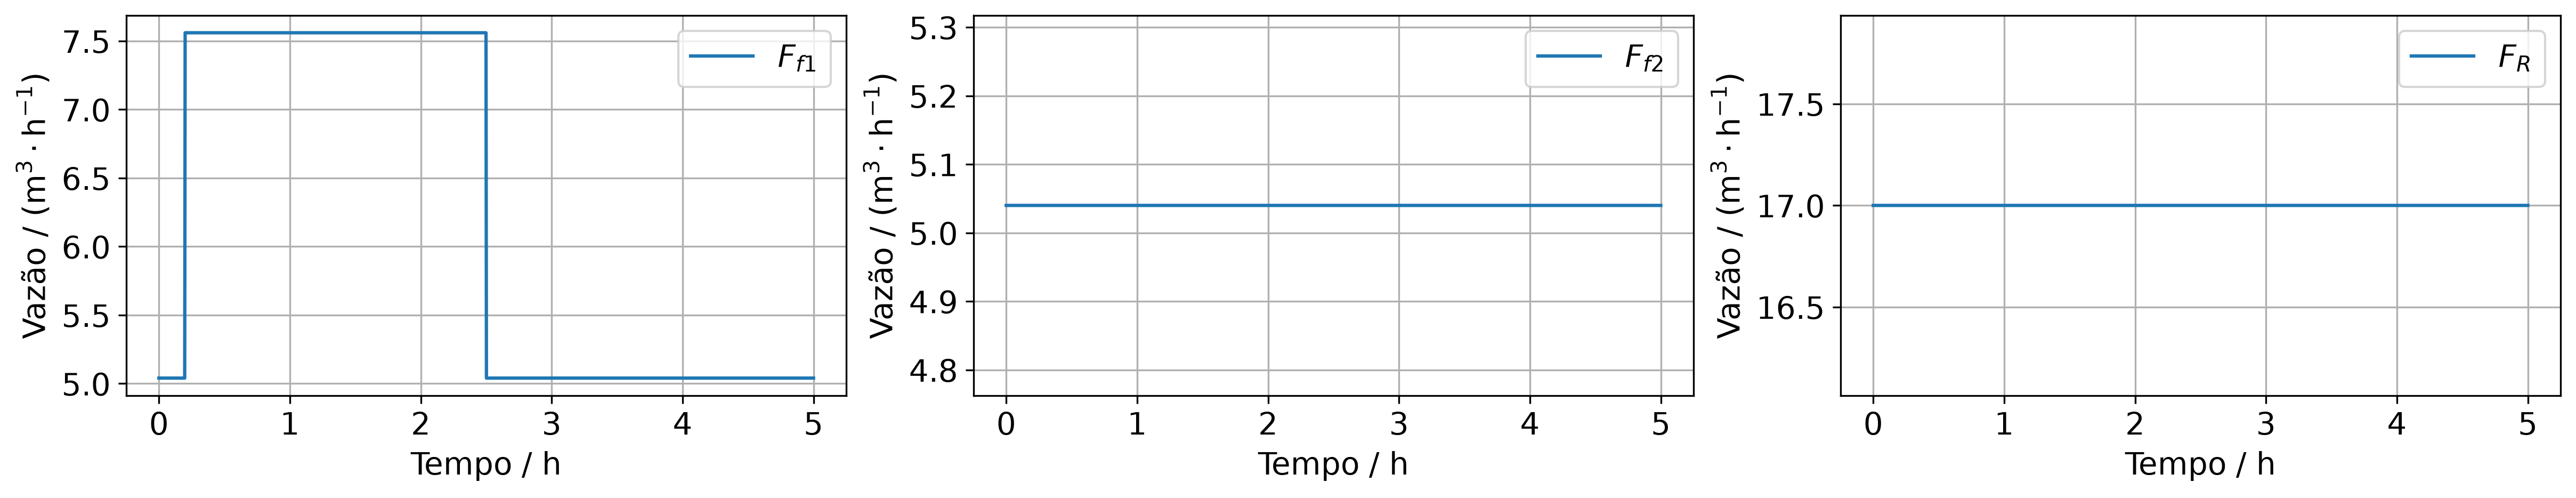

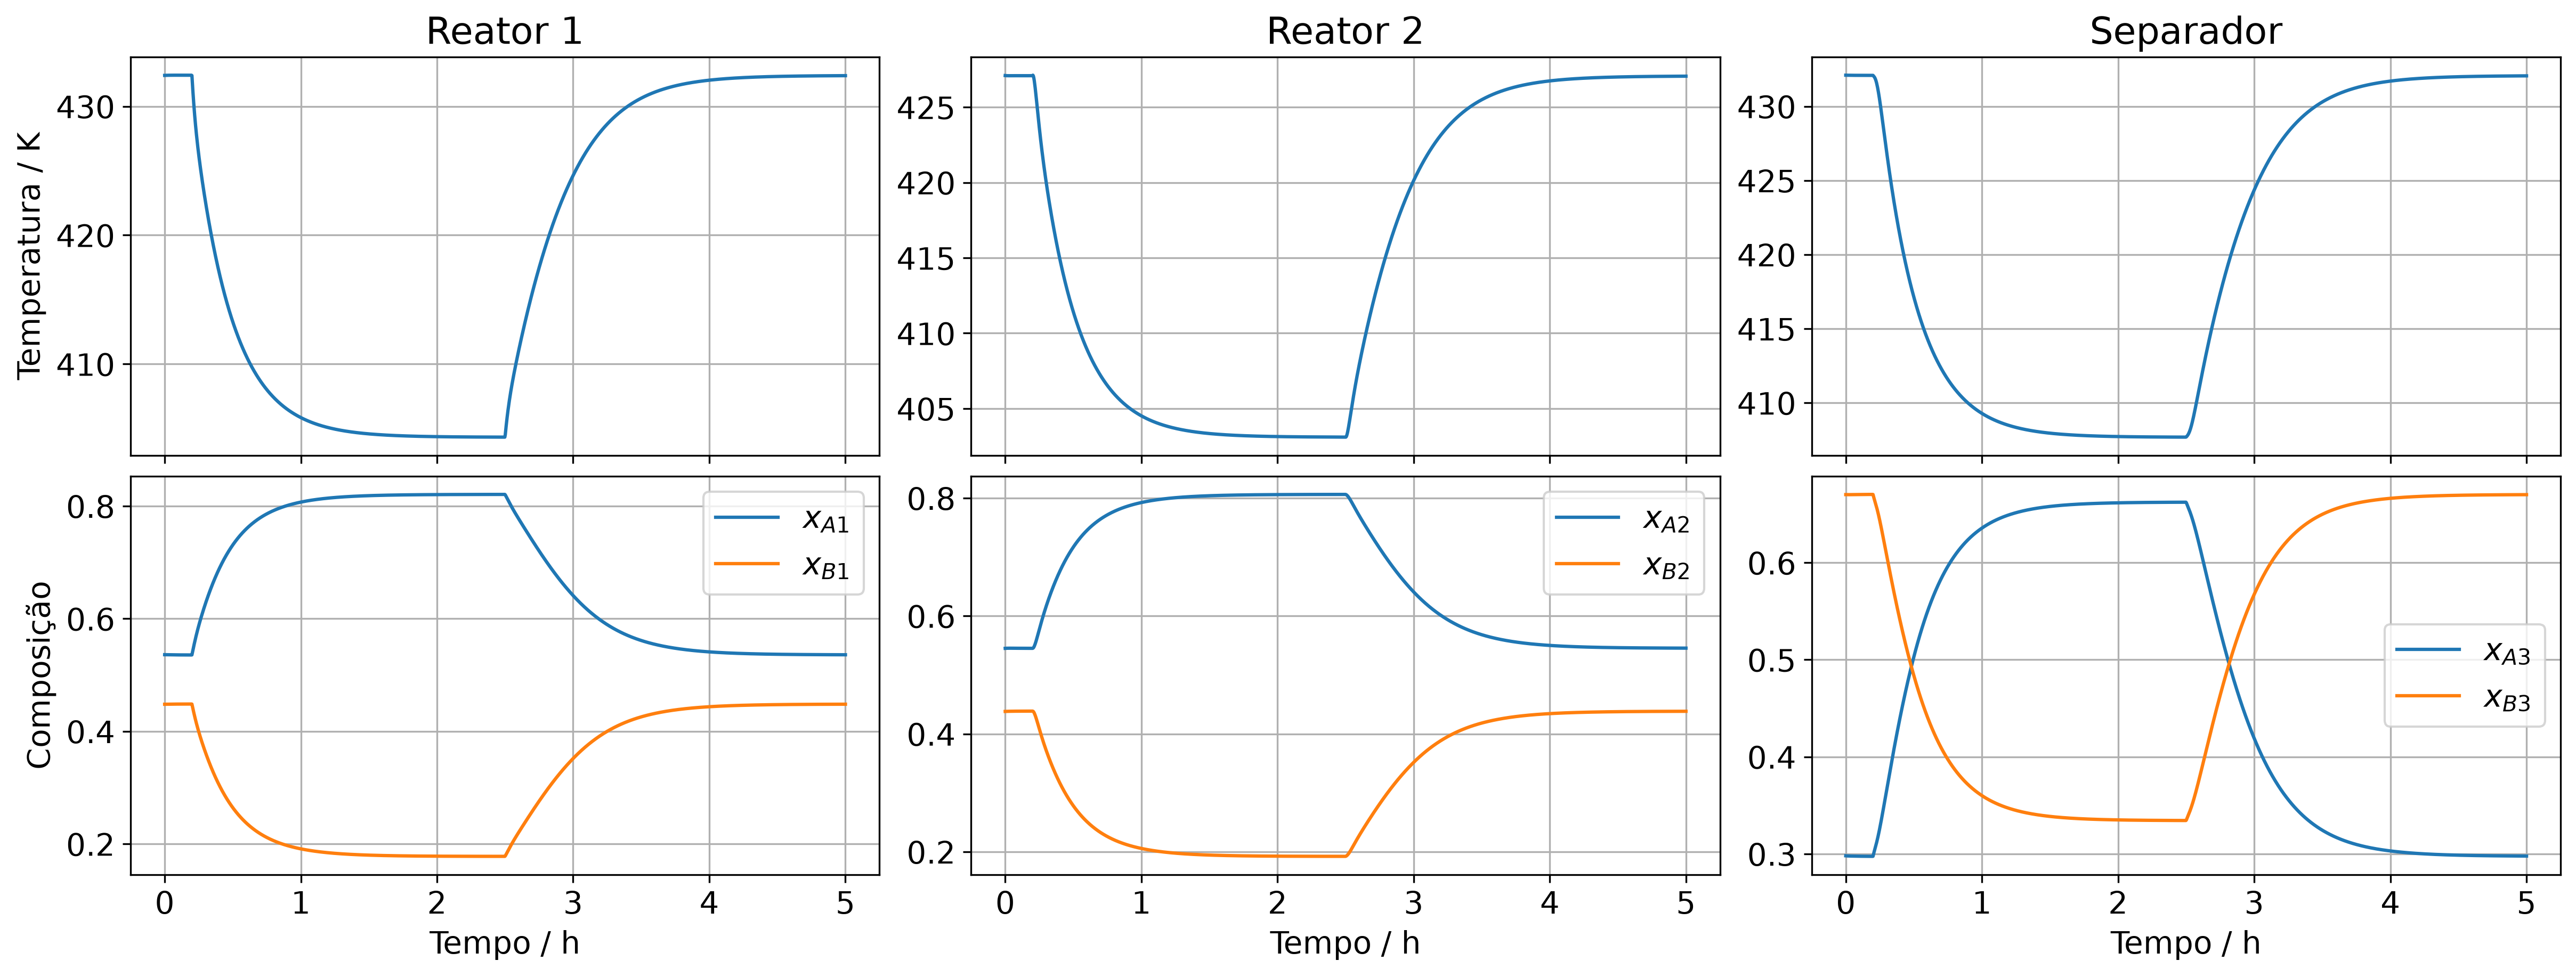

Pulso em Ff2: entradas e saídas do sistema não linear


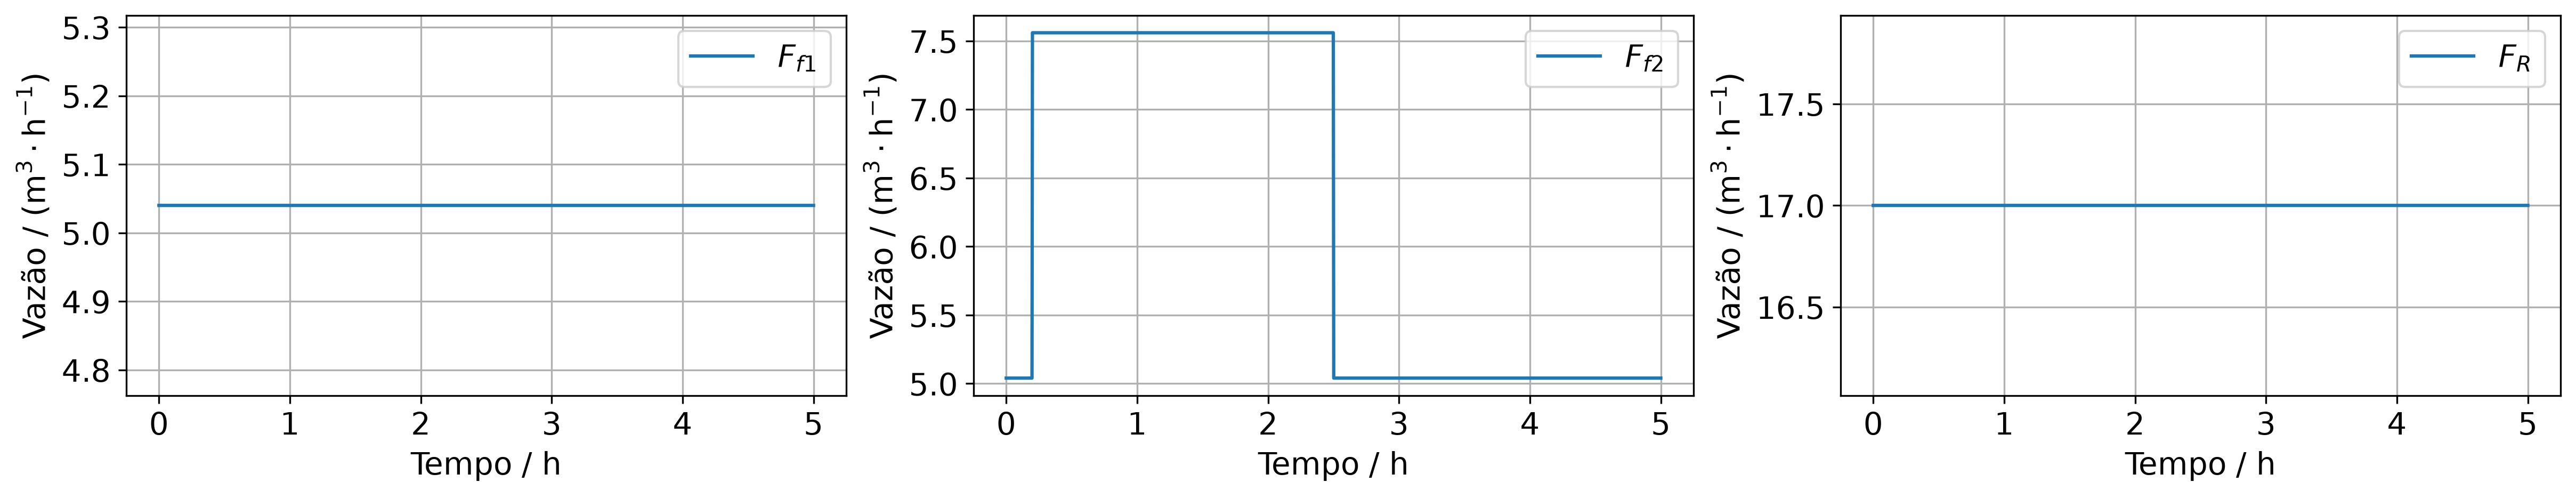

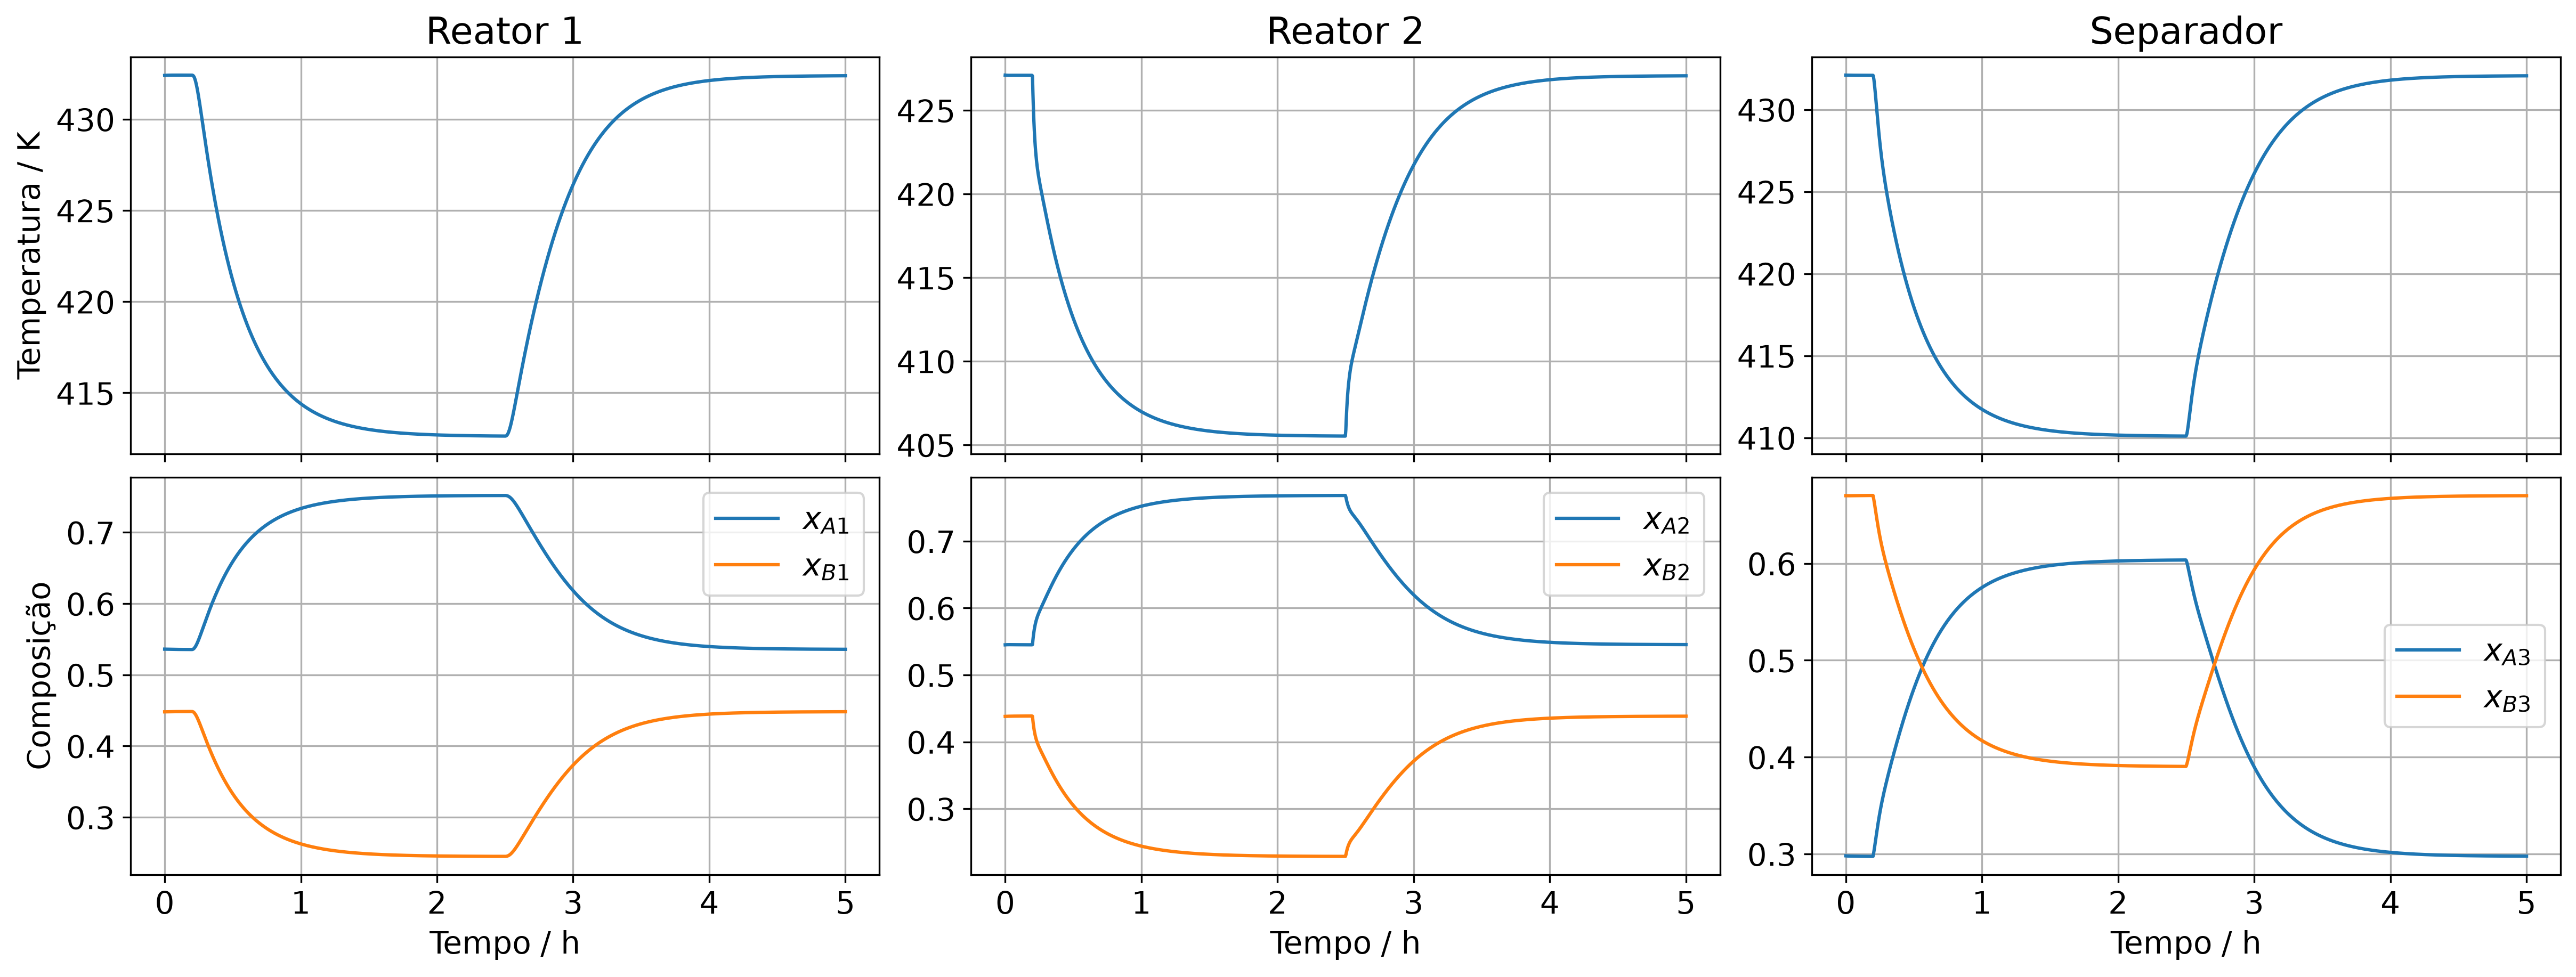

Pulso em FR: entradas e saídas do sistema não linear


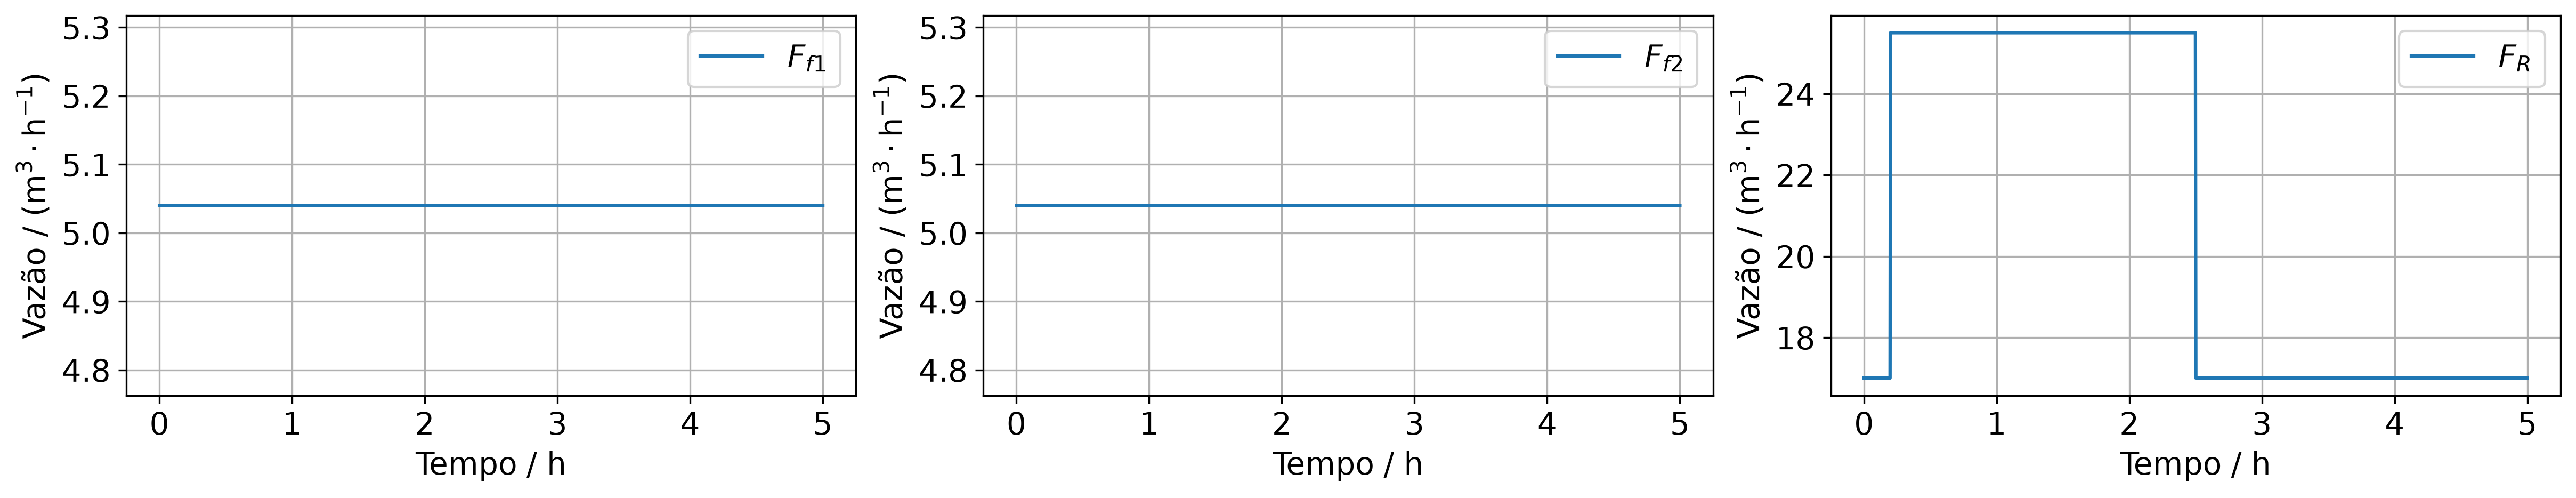

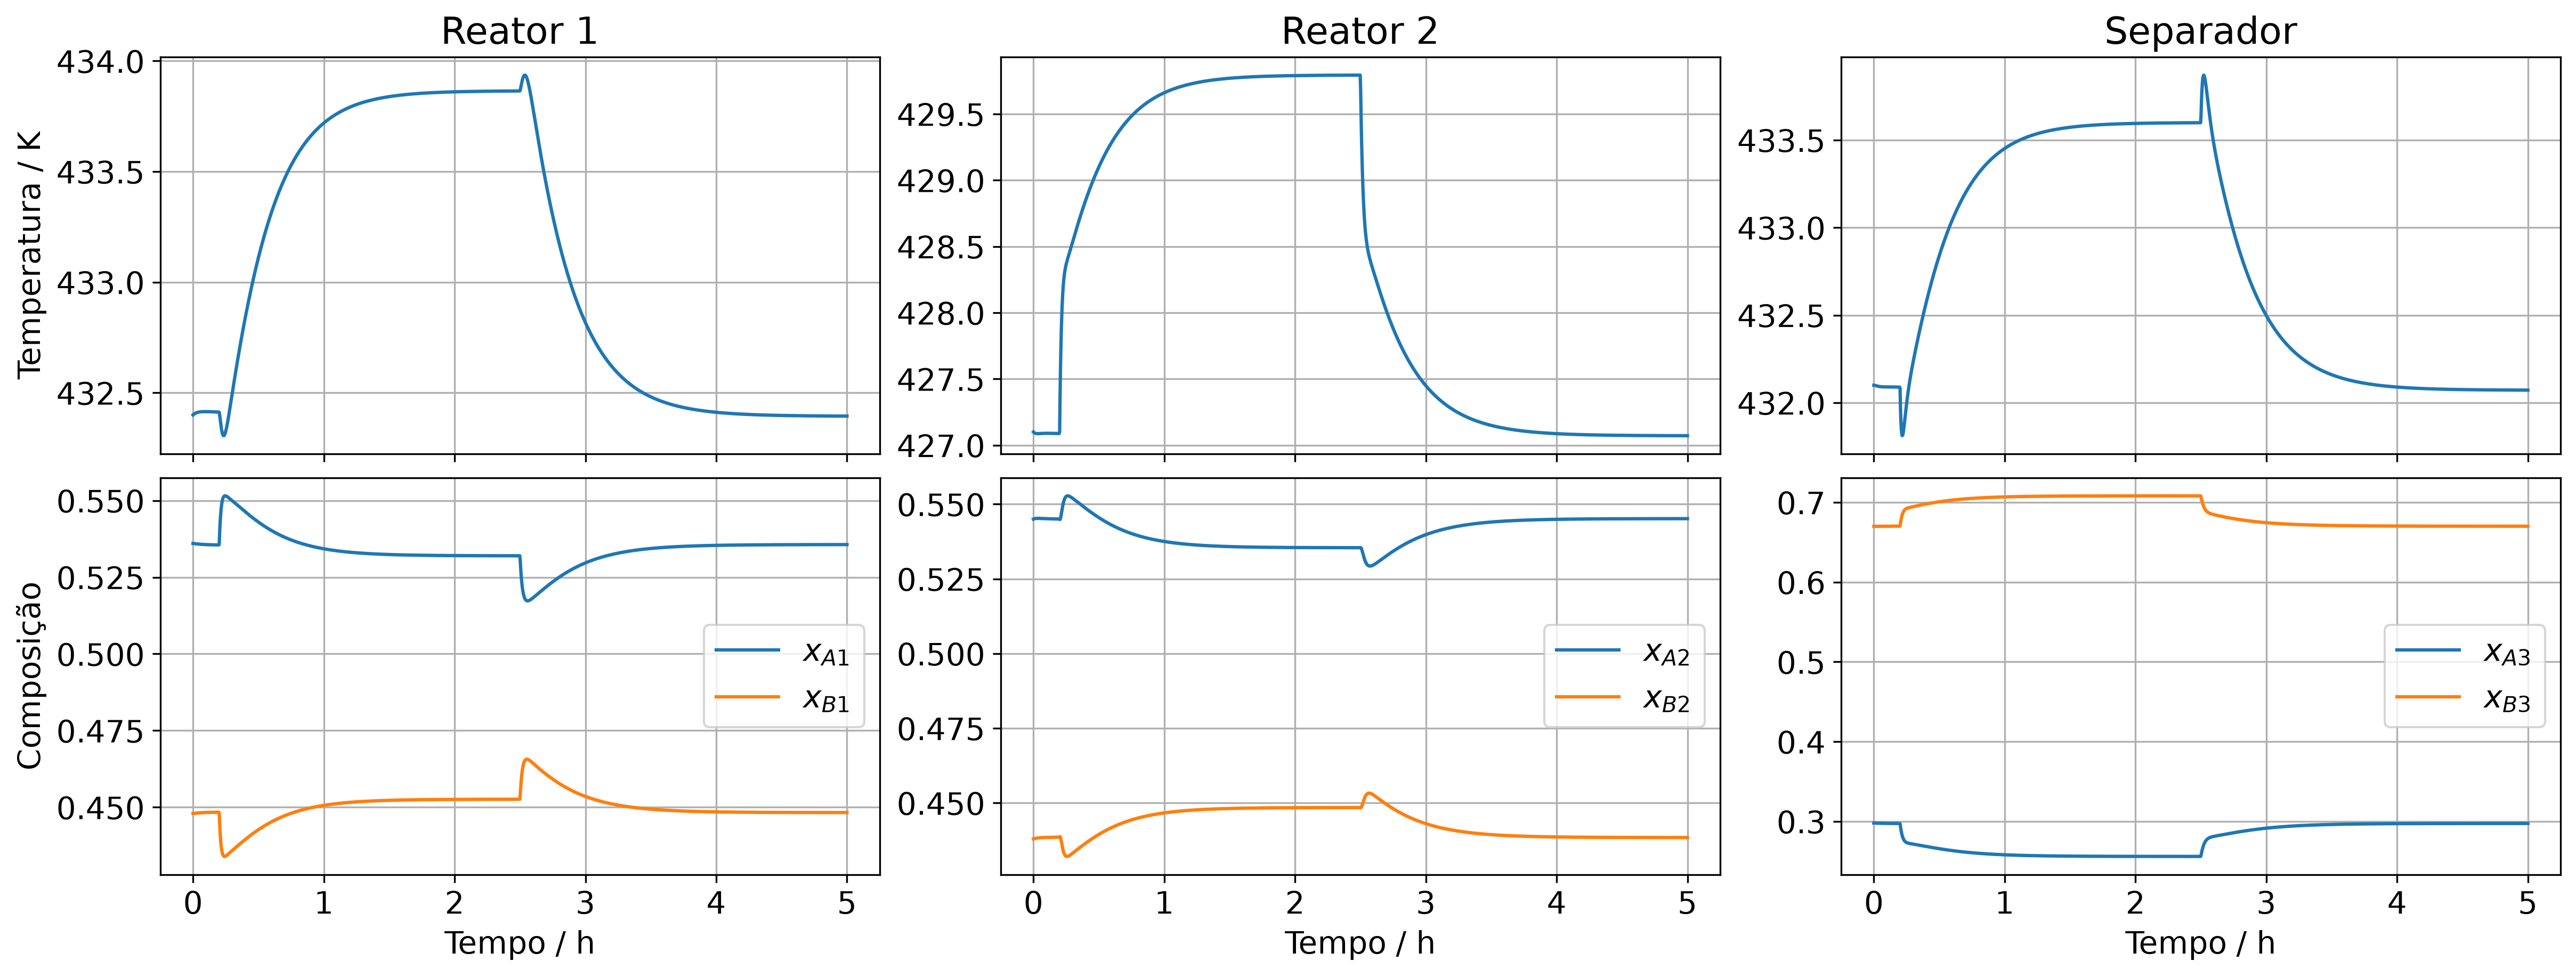

In [1]:
import numpy as np
from scipy.integrate import solve_ivp

from lib.inputs import Ff1_func, Ff2_func, FR_func
from lib.np_model import model
from lib.parameters import y0
from lib.plots import plot_system_inputs, plot_system_outputs
from lib.utils import input_names

base_funcs = [Ff1_func, Ff2_func, FR_func]

t = np.linspace(0, 5, 1500)

for idx, name in enumerate(input_names):
    u = list(base_funcs)
    u[idx] = lambda t, f=base_funcs[idx]: f(t, disturb=True)  # type: ignore

    sol = solve_ivp(
        model, [t[0], t[-1]], y0, t_eval=t, args=(u,), rtol=1e-10, atol=1e-10
    )

    u_eval = [ui(t) for ui in u]

    print(f"Pulso em {name}: entradas e saídas do sistema não linear")
    plot_system_inputs(t, u_eval, f"nonlinear/pulse-{name}-inputs")
    plot_system_outputs(t, sol.y, f"nonlinear/pulse-{name}-outputs")
